In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

In [2]:
data_path = Path("data/26MAG_HW_1_v3.xls")

columns = [
    "Возраст",
    "Иждивенцы",
    "Доход",
    "Срок проживания",
    "Стоимость автомобиля",
    "Размер кредита",
]

df = pd.read_excel(
    data_path,
    header=None,
    names=columns,
)

print(df)
print(f"\nКлиентов: {df.shape[0]}, признаков: {df.shape[1]}")

    Возраст  Иждивенцы    Доход  Срок проживания  Стоимость автомобиля  \
0      40.0        1.0   2900.0             11.0                2000.0   
1      56.0        4.0  16400.0             20.0               20000.0   
2      55.0        4.0  22600.0             19.0               26000.0   
3       NaN        2.0   6300.0             13.0                7000.0   
4      54.0        4.0  25400.0             18.0               28000.0   
5      51.0        3.0  17600.0             17.0               20000.0   
6      40.0        2.0  12900.0             10.0               13000.0   
7      51.0        3.0   7100.0             17.0                9000.0   
8      44.0        2.0      NaN             13.0               17000.0   
9      49.0        3.0  14900.0             16.0               17000.0   
10     35.0        NaN  29400.0              6.0               29000.0   
11     21.0        3.0   8200.0             11.0               48000.0   
12     32.0        2.0  37100.0       

### 1.1 Основные характеристики признаков

При вычислении пропуски исключаются отдельно для каждого признака.

In [3]:
stats = pd.DataFrame(
    {
        "# наблюдений": df.count(),
        "# пропусков": df.isna().sum(),
        "Среднее": df.mean(skipna=True),
        "Стандартное отклонение": df.std(skipna=True),
        "Медиана": df.median(skipna=True),
        "Q1 (25%)": df.quantile(0.25),
        "Q3 (75%)": df.quantile(0.75),
    }
)

stats.round(2)

,# наблюдений,# пропусков,Среднее,Стандартное отклонение,Медиана,Q1 (25%),Q3 (75%)
Возраст,40,2,38.78,9.05,39.0,31.75,44.0
Иждивенцы,40,2,2.00,1.09,2.0,1.00,3.0
Доход,40,2,19360.00,10264.97,19450.0,12400.00,27050.0
Срок проживания,40,2,10.20,4.97,10.5,5.00,13.0
Стоимость автомобиля,40,2,21325.00,11899.98,20000.0,14750.00,28000.0
Размер кредита,40,2,196025.00,97304.30,195000.0,149500.00,261750.0


### 1.2. Гистограммы признаков

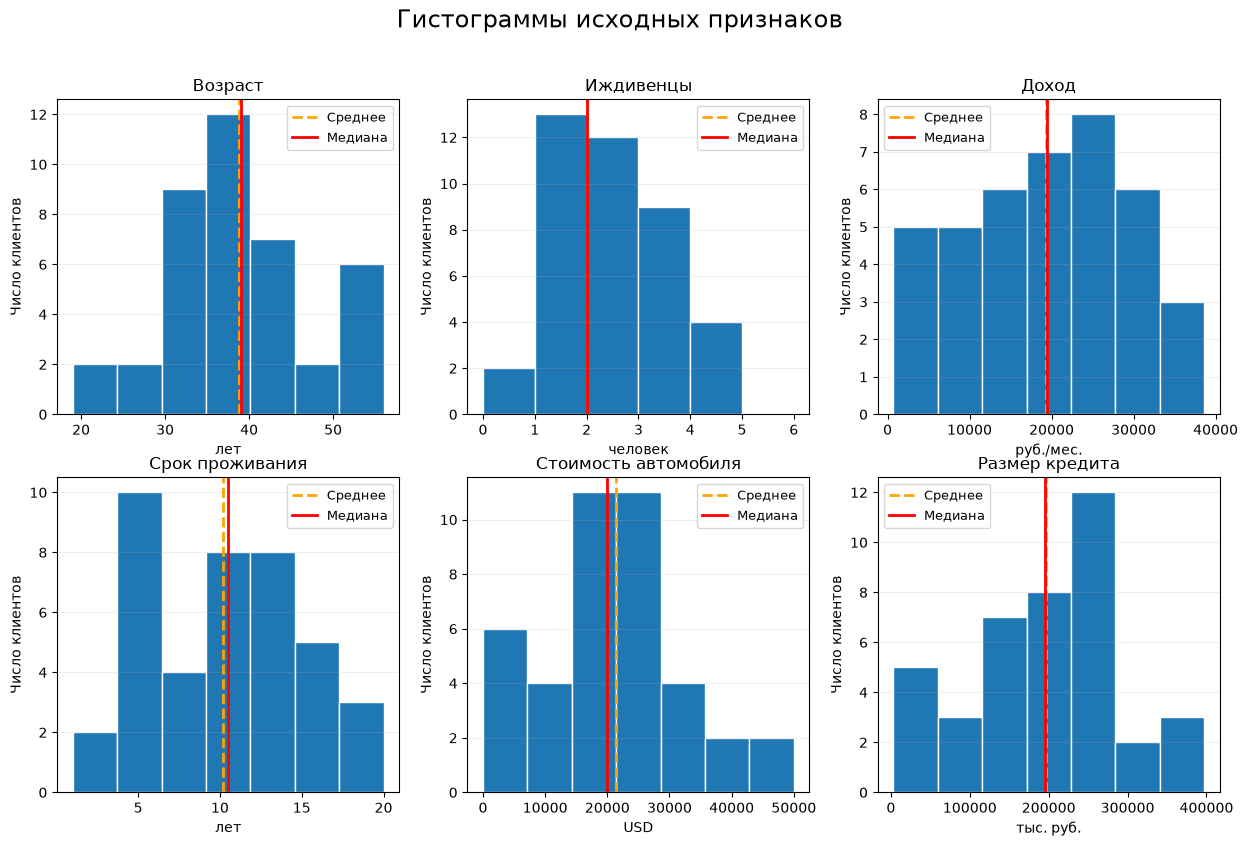

In [4]:
units = {
    "Возраст": "лет",
    "Иждивенцы": "человек",
    "Доход": "руб./мес.",
    "Срок проживания": "лет",
    "Стоимость автомобиля": "USD",
    "Размер кредита": "тыс. руб.",
}

fig_hist, axes = plt.subplots(2, 3, figsize=(15, 9))
fig_hist.suptitle("Гистограммы исходных признаков", fontsize=17)

for ax, column in zip(axes.flat, df.columns):
    values = df[column].dropna()
    if column == "Иждивенцы":
        ax.hist(values, bins=range(0, 7), edgecolor="white")
    else:
        ax.hist(values, bins="auto", edgecolor="white")
    ax.axvline(
        values.mean(), color="orange", linestyle="--", linewidth=2, label="Среднее"
    )
    ax.axvline(values.median(), color="red", linewidth=2, label="Медиана")
    ax.set_title(f"{column}")
    ax.set_xlabel(units[column])
    ax.set_ylabel("Число клиентов")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=9)

plt.show()

На графиках выше видно, что данные распределены неравномерно: они скорее сконцентрированы около среднего значения.
Это особенно заметно во всех случаях, кроме срока проживания.
В его случае гистограмма имеет два явных пика: около 4–6 и 10–14 лет.

Распределения не выглядят строго симметричными. По этим гистограммам нельзя точно считать их нормальными: наличие пика около среднего само по себе этого не доказывает. Особенно при таком низком размере выборки.

### 1.3. Блок-диаграммы признаков

Также построим блок-диаграммы исходных данных. Линия внутри ящика обозначает медиану, границы ящика -
первый и третий квартили. Усы доходят до крайних наблюдений внутри границ
$Q_1 - 1.5\cdot IQR$ и $Q_3 + 1.5\cdot IQR$, значения за ними показаны
отдельными точками.

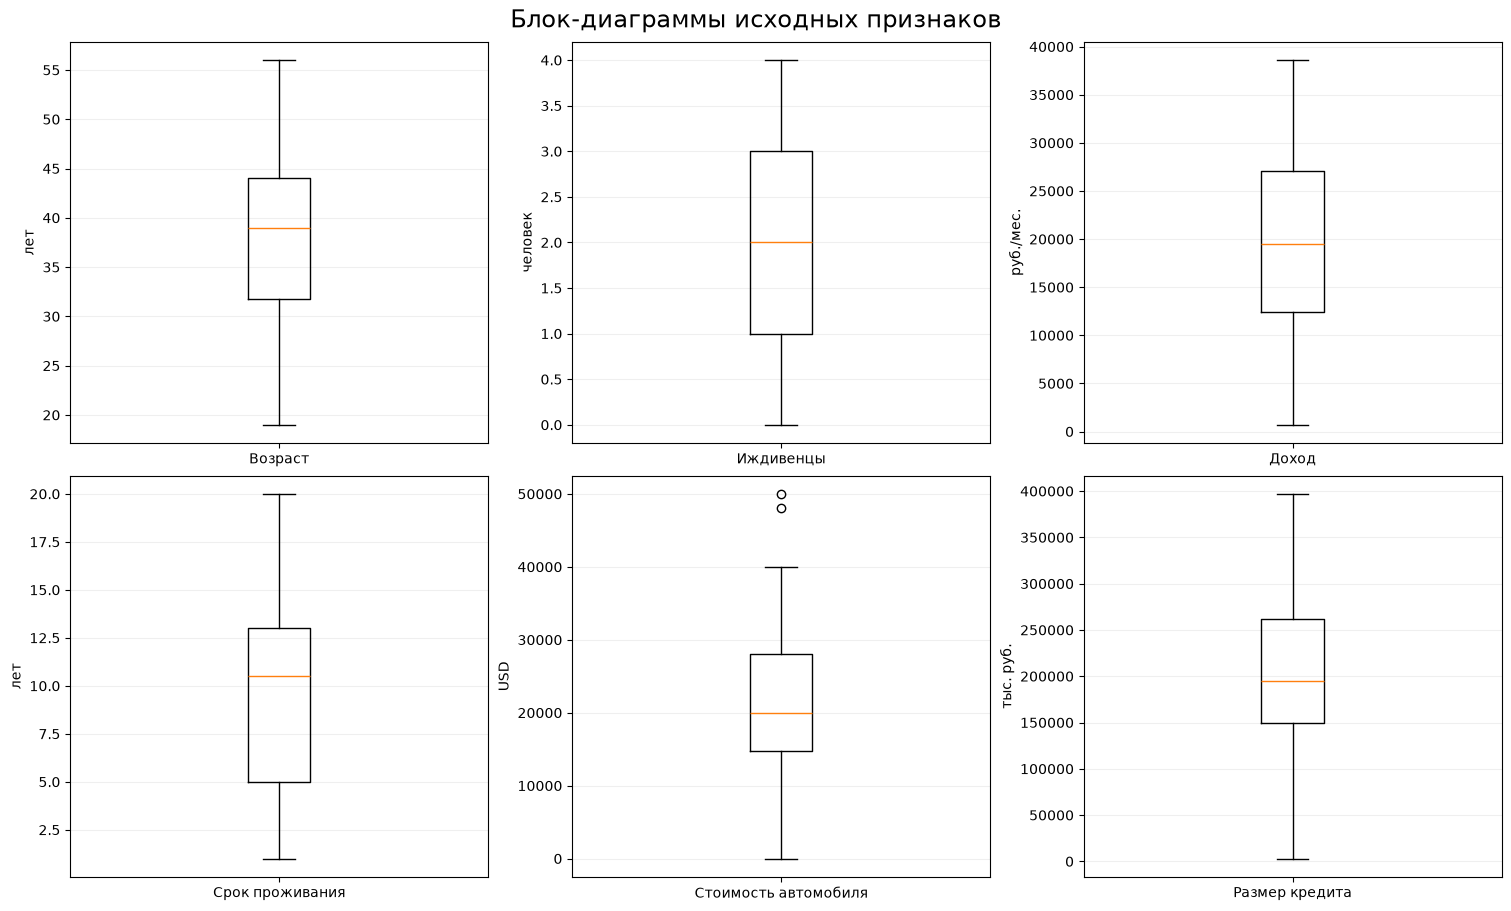

In [34]:
fig_boxplots, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
fig_boxplots.suptitle("Блок-диаграммы исходных признаков", fontsize=17)

for ax, column in zip(axes.flat, df.columns):
    ax.boxplot(
        df[column].dropna(),
        whis=1.5,
        tick_labels=[column],
    )
    ax.set_ylabel(units[column])
    ax.grid(axis="y", alpha=0.2)

plt.show()

На блок-диаграмме стоимости автомобиля отдельно выделяются значения
48 000 и 50 000 USD. У остальных признаков наблюдений за границами
$1.5\cdot IQR$ нет.

Также можно заметить, что медиана расположена посередине ящика для числа иждивенцев и близко к середине для дохода. В случае возраста она немного смещена к большим значениям, а для срока проживания этот сдвиг выражен сильнее. Для стоимости автомобиля и размера кредита медиана смещена к меньшим значениям примерно в одинаковой степени относительно межквартильного размаха.

Эти сдвиги показывают различие разброса значений между первым квартилем и медианой и между медианой и третьим квартилем. Однако положение медианы внутри ящика само по себе не позволяет сделать вывод о симметрии всего распределения: нужно учитывать также усы, крайние наблюдения и гистограммы.

### 2. Заполнение пропусков

Для заполнения пропусков используем медиану каждого признака.
Вычислим ее по непустым значениям столбца и подставляем вместо `NaN`.

Причины выбора медианы:
- В данных есть крайние значения, например дорогие автомобили. Медиана
  менее чувствительна к их величине, чем среднее.
- Нормальность распределений не доказана. Медианное заполнение
  не требует предположения о нормальном распределении.
- Пропусков немного: в каждом признаке всего 2.

In [5]:
missing_before = df.isna().sum()
medians = df.median(skipna=True)

df_filled = df.fillna(medians)

imputation_summary = pd.DataFrame(
    {
        "Медиана для заполнения": medians,
        "Пропусков до": missing_before,
        "Пропусков после": df_filled.isna().sum(),
    }
)
imputation_summary

,Медиана для заполнения,Пропусков до,Пропусков после
Возраст,39.0,2,0
Иждивенцы,2.0,2,0
Доход,19450.0,2,0
Срок проживания,10.5,2,0
Стоимость автомобиля,20000.0,2,0
Размер кредита,195000.0,2,0


In [6]:
df_filled

,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита
0,40.0,1.0,2900.0,11.0,2000.0,25000.0
1,56.0,4.0,16400.0,20.0,20000.0,184000.0
2,55.0,4.0,22600.0,19.0,26000.0,246000.0
3,39.0,2.0,6300.0,13.0,7000.0,65000.0
4,54.0,4.0,25400.0,18.0,28000.0,274000.0
5,51.0,3.0,17600.0,17.0,20000.0,190000.0
6,40.0,2.0,12900.0,10.0,13000.0,127000.0
7,51.0,3.0,7100.0,17.0,9000.0,82000.0
8,44.0,2.0,19450.0,13.0,17000.0,165000.0
9,49.0,3.0,14900.0,16.0,17000.0,159000.0


### 3. Определение и удаление выбросов

Используем правило Тьюки на основе межквартильного размаха.

Для каждого признака вычисляем первый и третий квартили, затем:

$$IQR = Q_3 - Q_1,$$
$$L = Q_1 - 1.5\cdot IQR, \qquad U = Q_3 + 1.5\cdot IQR.$$

Значение считаем выбросом, если оно строго меньше $L$ или больше $U$.
Удаляем объект целиком, если хотя бы один из его признаков является
выбросом по этому правилу.

Причины выбора метода:
- Квартили менее чувствительны к крайним значениям, чем среднее и
  стандартное отклонение.
- Метод не требует предположения о нормальном распределении.

In [7]:
q1 = df_filled.quantile(0.25)
q3 = df_filled.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_features = df_filled.lt(lower_bound) | df_filled.gt(upper_bound)
outlier_objects = outlier_features.any(axis=1)

outlier_summary = pd.DataFrame(
    {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Нижняя граница": lower_bound,
        "Верхняя граница": upper_bound,
        "# выбросов": outlier_features.sum(),
    }
)
outlier_summary.round(2)

,Q1,Q3,IQR,Нижняя граница,Верхняя граница,# выбросов
Возраст,32.00,43.75,11.75,14.38,61.38,0
Иждивенцы,1.00,3.00,2.00,-2.00,6.00,0
Доход,13400.00,26800.00,13400.00,-6700.00,46900.00,0
Срок проживания,5.25,13.00,7.75,-6.38,24.62,0
Стоимость автомобиля,15250.00,27750.00,12500.00,-3500.00,46500.00,2
Размер кредита,152250.00,261000.00,108750.00,-10875.00,424125.00,0


In [8]:
df_outliers = df_filled.loc[outlier_objects].copy()
df_outliers["Признаки вне границ"] = outlier_features.loc[outlier_objects].apply(
    lambda row: ", ".join(row.index[row]),
    axis=1,
)
df_outliers

,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита,Признаки вне границ
11,21.0,3.0,8200.0,11.0,48000.0,250000.0,Стоимость автомобиля
32,19.0,2.0,8000.0,12.0,50000.0,200000.0,Стоимость автомобиля


In [9]:
df_clean = df_filled.loc[~outlier_objects].copy()

print(f"Удалено клиентов: {outlier_objects.sum()} из {len(df_filled)}")
print(f"Осталось клиентов: {len(df_clean)}")
df_clean

Удалено клиентов: 2 из 42
Осталось клиентов: 40


,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита
0,40.0,1.0,2900.0,11.0,2000.0,25000.0
1,56.0,4.0,16400.0,20.0,20000.0,184000.0
2,55.0,4.0,22600.0,19.0,26000.0,246000.0
3,39.0,2.0,6300.0,13.0,7000.0,65000.0
4,54.0,4.0,25400.0,18.0,28000.0,274000.0
5,51.0,3.0,17600.0,17.0,20000.0,190000.0
6,40.0,2.0,12900.0,10.0,13000.0,127000.0
7,51.0,3.0,7100.0,17.0,9000.0,82000.0
8,44.0,2.0,19450.0,13.0,17000.0,165000.0
9,49.0,3.0,14900.0,16.0,17000.0,159000.0


Удалены объекты с индексом 11 и 32. Стоимость их автомобилей равна
48000 и 50000 USD, что превышает верхнюю границу в 46500.
У остальных признаков выбросов нет.

### 4. Центрирование и нормировка данных

Для каждого признака вычитаем среднее и нормируем столбцы:

$$A_{ij}=x_{ij}-\overline{x}_j,\qquad
c_j=\sqrt{\sum_{i=1}^{n}A_{ij}^2},\qquad Z_{ij}=\frac{A_{ij}}{c_j}.$$

In [10]:
client_ids_pca = pd.Index(df_clean.index + 1, name="Клиент")
X_pca = df_clean.to_numpy(dtype=float)

feature_means = X_pca.mean(axis=0)
X_centered = X_pca - feature_means
column_norms = np.linalg.norm(X_centered, axis=0)

Z = X_centered / column_norms

normalization_summary = pd.DataFrame(
    {
        "Среднее до центрирования": feature_means,
        "Норма центрированного столбца": column_norms,
        "Среднее столбца Z": Z.mean(axis=0),
        "Норма столбца Z": np.linalg.norm(Z, axis=0),
    },
    index=df_clean.columns,
)
normalization_summary

,Среднее до центрирования,Норма центрированного столбца,Среднее столбца Z,Норма столбца Z
Возраст,39.725,49.517421,-2.775558e-17,1.0
Иждивенцы,1.975,6.706340,-1.318390e-17,1.0
Доход,19927.500,61991.569991,0.000000e+00,1.0
Срок проживания,10.150,30.961266,-1.526557e-17,1.0
Стоимость автомобиля,19875.000,62516.997689,-1.387779e-18,1.0
Размер кредита,194525.000,605177.639210,-5.551115e-18,1.0


In [11]:
Z_frame = pd.DataFrame(
    Z,
    index=client_ids_pca,
    columns=df_clean.columns,
)
Z_frame

,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита
Клиент,,,,,,
1,0.005554,-0.145385,-0.274674,0.027454,-0.285922,-0.280124
2,0.328672,0.301953,-0.056903,0.318139,0.001999,-0.017392
3,0.308477,0.301953,0.043111,0.285841,0.097973,0.085058
4,-0.014641,0.003728,-0.219828,0.092050,-0.205944,-0.214028
5,0.288282,0.301953,0.088278,0.253543,0.129965,0.131325
6,0.227698,0.152840,-0.037545,0.221244,0.001999,-0.007477
7,0.005554,0.003728,-0.113362,-0.004845,-0.109970,-0.111579
8,0.227698,0.152840,-0.206923,0.221244,-0.173953,-0.185937
9,0.086333,0.003728,-0.007703,0.092050,-0.045987,-0.048787


### 5. Сингулярное разложение матрицы Z

Вычислим SVD:

$$Z=USV^T,\qquad U\in\mathbb R^{40\times6},\quad S,V\in\mathbb R^{6\times6}.$$

Столбцы $U$ и $V$ ортонормированы, диагональ $S$ содержит сингулярные значения $\sigma_1\geq\dots\geq\sigma_6\geq0$.

In [12]:
U, singular_values, Vt = np.linalg.svd(Z, full_matrices=False)

S = np.diag(singular_values)
V = Vt.T
component_names = [f"PC{i + 1}" for i in range(len(singular_values))]

reconstruction_error = np.linalg.norm(Z - U @ S @ Vt, ord="fro")

print(f"Размерность U: {U.shape}")
print(f"Размерность S: {S.shape}")
print(f"Размерность V: {V.shape}")
print(f"Норма Фробениуса разности матриц Z и USVᵀ: {reconstruction_error:.3e}")

Размерность U: (40, 6)
Размерность S: (6, 6)
Размерность V: (6, 6)
Норма Фробениуса разности матриц Z и USVᵀ: 1.297e-15


In [13]:
U_frame = pd.DataFrame(
    U,
    index=client_ids_pca,
    columns=component_names,
)
U_frame

,PC1,PC2,PC3,PC4,PC5,PC6
Клиент,,,,,,
1,-0.212829,0.203644,-0.154542,-0.102481,-0.069001,-0.005378
2,-0.192185,-0.263361,-0.051458,0.017910,0.053733,-0.027203
3,-0.101906,-0.307053,-0.089194,0.015970,0.049692,-0.004224
4,-0.187495,0.102654,0.158896,0.154831,-0.351278,-0.245927
5,-0.057768,-0.316654,-0.072497,0.049468,0.101557,0.100299
6,-0.125039,-0.164879,-0.196902,-0.063094,-0.058217,-0.054515
7,-0.089017,0.063123,0.114604,0.043256,0.196269,0.031761
8,-0.263395,-0.063406,-0.015758,-0.008355,0.126803,0.031535
9,-0.065153,-0.028270,-0.159301,-0.190279,-0.254587,0.264755


In [14]:
S_frame = pd.DataFrame(
    S,
    index=component_names,
    columns=component_names,
)
S_frame

,PC1,PC2,PC3,PC4,PC5,PC6
PC1,1.78377,0.000000,0.000000,0.000000,0.00000,0.000000
PC2,0.00000,1.638433,0.000000,0.000000,0.00000,0.000000
PC3,0.00000,0.000000,0.261918,0.000000,0.00000,0.000000
PC4,0.00000,0.000000,0.000000,0.202057,0.00000,0.000000
PC5,0.00000,0.000000,0.000000,0.000000,0.12121,0.000000
PC6,0.00000,0.000000,0.000000,0.000000,0.00000,0.097893


In [15]:
V_frame = pd.DataFrame(
    V,
    index=df_clean.columns,
    columns=component_names,
)
V_frame

,PC1,PC2,PC3,PC4,PC5,PC6
Возраст,-0.359707,-0.458296,-0.459342,-0.372907,0.513117,0.217327
Иждивенцы,-0.202980,-0.555827,0.714755,0.309347,0.192463,0.079014
Доход,0.494927,-0.277796,0.129077,-0.413923,-0.344483,0.609274
Срок проживания,-0.401866,-0.419835,-0.247731,0.068427,-0.748580,-0.189254
Стоимость автомобиля,0.448941,-0.360118,0.056204,-0.354800,0.094133,-0.728604
Размер кредита,0.470545,-0.312895,-0.443779,0.680696,0.108476,0.092896


### 6. Исследование числа главных факторов

Доля дисперсии компоненты пропорциональна квадрату её сингулярного значения:

$$p_j=\frac{\sigma_j^2}{\sum_{\ell=1}^{6}\sigma_\ell^2},\qquad
P_k=\sum_{j=1}^{k}p_j.$$

У $Z$ шесть столбцов единичной нормы, поэтому $\|Z\|_F^2=\sum_j\sigma_j^2=6$. Рассмотрим суммарную долю дисперсии для всех $k$ от 1 до 6.

In [16]:
explained_variance = singular_values**2 / np.sum(singular_values**2)
cumulative_variance = np.cumsum(explained_variance)

variance_summary = pd.DataFrame(
    {
        "Сингулярное значение": singular_values,
        "Доля дисперсии, %": 100 * explained_variance,
        "Суммарная доля, %": 100 * cumulative_variance,
    },
    index=component_names,
)

variance_summary.round(6)

,Сингулярное значение,"Доля дисперсии, %","Суммарная доля, %"
PC1,1.783770,53.030584,53.030584
PC2,1.638433,44.741035,97.771619
PC3,0.261918,1.143351,98.914970
PC4,0.202057,0.680448,99.595418
PC5,0.121210,0.244864,99.840282
PC6,0.097893,0.159718,100.000000


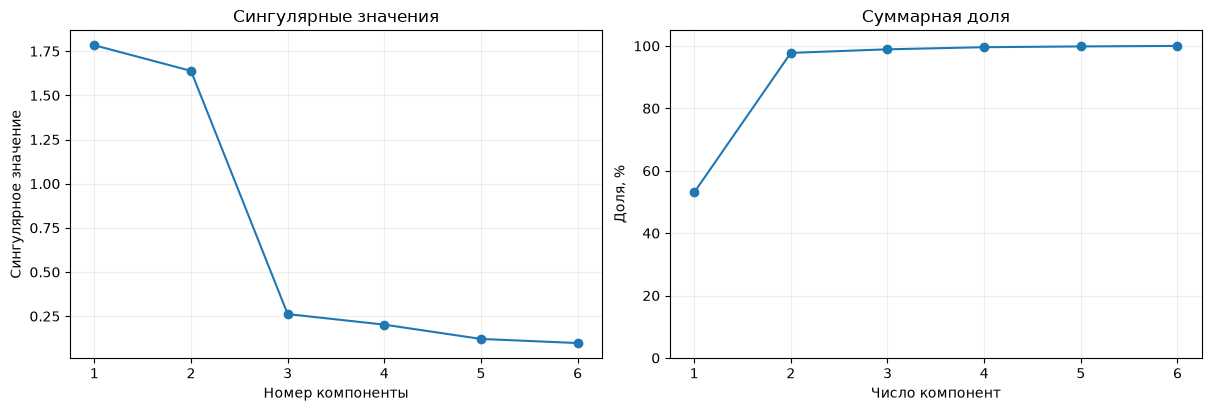

In [17]:
component_numbers = np.arange(1, len(singular_values) + 1)

fig_variance, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

axes[0].plot(component_numbers, singular_values, "o-")
axes[0].set_title("Сингулярные значения")
axes[0].set_xlabel("Номер компоненты")
axes[0].set_ylabel("Сингулярное значение")

axes[1].plot(component_numbers, 100 * cumulative_variance, "o-")
axes[1].set_title("Суммарная доля")
axes[1].set_xlabel("Число компонент")
axes[1].set_ylabel("Доля, %")
axes[1].set_ylim(0, 105)

for ax in axes:
    ax.set_xticks(component_numbers)
    ax.grid(alpha=0.2)

plt.show()

Первые две компоненты объясняют почти всю дисперсию данных (97.77%)

### 7. Аппроксимация матрицы и её погрешность

Представим каждый нормированный признак линейной комбинацией первых $k$ главных факторов (столбцов $U$):

$$(Z_k)_{*,j}=\sum_{\ell=1}^{k}\sigma_\ell v_{j\ell}u_\ell.$$

Коэффициенты этих комбинаций образуют матрицу $S_kV_k^T$, поэтому

$$Z_k=U_kS_kV_k^T=\sum_{\ell=1}^{k}\sigma_\ell u_\ell v_\ell^T.$$

Матрица $Z_k$ имеет размер $40\times6$. Координаты клиентов в пространстве главных компонент задаются матрицей $T=U_kS_k=ZV_k$.

При сохранении первых $k$ слагаемых SVD получаем наилучшую аппроксимацию ранга не выше $k$ в операторной норме и норме Фробениуса:

$$\|Z-Z_k\|_2=\sigma_{k+1},\qquad
\|Z-Z_k\|_F=\sqrt{\sum_{j=k+1}^{6}\sigma_j^2}.$$

Сравним вычисленные и теоретические значения для всех $k$ от 1 до 6. При $k=6$ обе теоретические ошибки равны нулю.

In [18]:
error_rows = []

for rank in component_numbers:
    approximation = (U[:, :rank] * singular_values[:rank]) @ Vt[:rank, :]
    residual = Z - approximation

    operator_error = np.linalg.norm(residual, ord=2)
    frobenius_error = np.linalg.norm(residual, ord="fro")
    operator_theory = singular_values[rank] if rank < len(singular_values) else 0.0
    frobenius_theory = np.linalg.norm(singular_values[rank:])
    relative_frobenius_error = frobenius_error / np.linalg.norm(Z, ord="fro")

    error_rows.append(
        {
            "k": rank,
            "Операторная норма": operator_error,
            "Операторная норма (теор. оценка)": operator_theory,
            "Норма Фробениуса": frobenius_error,
            "Норма Фробениуса (теор. оценка)": frobenius_theory,
            "Относительная погрешность Фробениуса": relative_frobenius_error,
        }
    )

pca_errors = pd.DataFrame(error_rows).set_index("k")
pca_errors.round(6)

,Операторная норма,Операторная норма (теор. оценка),Норма Фробениуса,Норма Фробениуса (теор. оценка),Относительная погрешность Фробениуса
k,,,,,
1,1.638433,1.638433,1.678739,1.678739,0.685342
2,0.261918,0.261918,0.365654,0.365654,0.149278
3,0.202057,0.202057,0.255151,0.255151,0.104165
4,0.121210,0.121210,0.155804,0.155804,0.063607
5,0.097893,0.097893,0.097893,0.097893,0.039965
6,0.000000,0.000000,0.000000,0.000000,0.000000


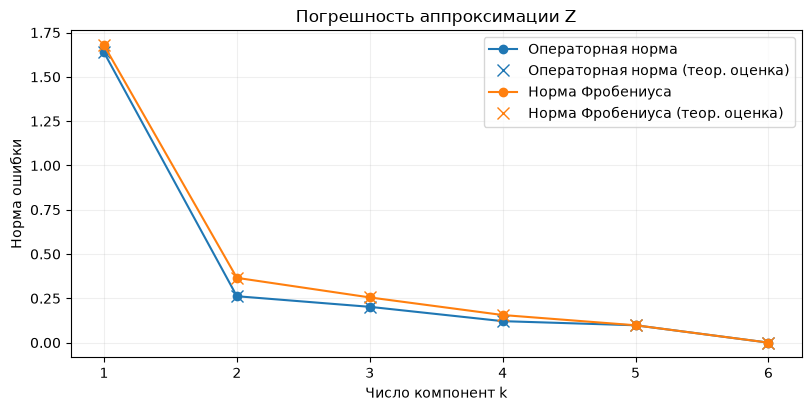

In [19]:
fig_errors, ax = plt.subplots(figsize=(8, 4), layout="constrained")

error_labels = [
    "Операторная норма",
    "Норма Фробениуса",
]

for label in error_labels:
    line, = ax.plot(
        pca_errors.index,
        pca_errors[label],
        "o-",
        label=label,
    )
    ax.plot(
        pca_errors.index,
        pca_errors[f"{label} (теор. оценка)"],
        "x",
        markersize=9,
        color=line.get_color(),
        label=f"{label} (теор. оценка)",
    )

ax.set_title("Погрешность аппроксимации Z")
ax.set_xlabel("Число компонент k")
ax.set_ylabel("Норма ошибки")
ax.set_xticks(component_numbers)
ax.grid(alpha=0.2)
ax.legend()

plt.show()

Вычисленные нормы разности совпадают с теоретическими значениями для всех $k$ с учётом округления. При $k=2$ операторная норма равна 0.261918, норма Фробениуса равна 0.365654.

Двух факторов достаточно для приближённого описания: они объясняют 97.77% дисперсии, а после второй компоненты сингулярные значения резко уменьшаются. Для дальнейшего анализа возьмем $k=2$.

Относительная погрешность в норме Фробениуса равна примерно 0.1493. Её квадрат равен примерно 0.0223 и соответствует доле дисперсии, не объяснённой первыми двумя компонентами.

Построим матрицу $Z_k$ с восстановленными значениями всех шести признаков по двум главным факторам. Её размер остаётся $40\times6$, а ранг равен 2.

In [20]:
k = 2

Z_pca = U[:, :k] * singular_values[:k]
Zk = Z_pca @ Vt[:k, :]

approximation_frame = pd.DataFrame(
    Zk,
    index=client_ids_pca,
    columns=df_clean.columns,
)

print(f"Размер Zk: {Zk.shape}")
approximation_frame

Размер Zk: (40, 6)


,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита
Клиент,,,,,,
1,-0.016355,-0.108397,-0.280581,0.012483,-0.290590,-0.283036
2,0.321068,0.309424,-0.049799,0.318924,0.001488,-0.026295
3,0.295949,0.316526,0.049789,0.284263,0.099563,0.071879
4,0.043222,-0.025600,-0.212250,0.063790,-0.210716,-0.209999
5,0.274837,0.309288,0.093125,0.259228,0.140573,0.113847
6,0.204035,0.195425,-0.035345,0.203048,-0.002849,-0.020425
7,0.009718,-0.025255,-0.107318,0.020390,-0.108530,-0.107077
8,0.216615,0.153111,-0.203676,0.232427,-0.173517,-0.188574
9,0.063032,0.049335,-0.044652,0.066150,-0.035495,-0.040193


In [21]:
factor_coefficients = pd.DataFrame(
    (S[:k, :k] @ Vt[:k, :]).T,
    index=df_clean.columns,
    columns=[f"u{i + 1}" for i in range(k)],
)

print("Коэффициенты линейных комбинаций главных факторов:")
factor_coefficients.round(4)

Коэффициенты линейных комбинаций главных факторов:


,u1,u2
Возраст,-0.6416,-0.7509
Иждивенцы,-0.3621,-0.9107
Доход,0.8828,-0.4551
Срок проживания,-0.7168,-0.6879
Стоимость автомобиля,0.8008,-0.5900
Размер кредита,0.8393,-0.5127


In [22]:
print(f"Ошибки для выбранного k = {k}:")
pca_errors.loc[[k]]

Ошибки для выбранного k = 2:


,Операторная норма,Операторная норма (теор. оценка),Норма Фробениуса,Норма Фробениуса (теор. оценка),Относительная погрешность Фробениуса
k,,,,,
2,0.261918,0.261918,0.365654,0.365654,0.149278


### 8. Представление клиентов и карта PCA

Строки $T=U_kS_k$ представляют клиентов в пространстве $k$ главных факторов. При выбранном $k=2$ это двумерная карта.

Приведём координаты клиентов, коэффициенты главных компонент и корреляции признаков с координатами.

In [23]:
pca_coordinates = pd.DataFrame(
    Z_pca,
    index=client_ids_pca,
    columns=component_names[:k],
)
pca_coordinates

,PC1,PC2
Клиент,,
1,-0.379637,0.333656
2,-0.342814,-0.431500
3,-0.181777,-0.503086
4,-0.334448,0.168192
5,-0.103046,-0.518816
6,-0.223041,-0.270143
7,-0.158786,0.103423
8,-0.469837,-0.103887
9,-0.116218,-0.046318


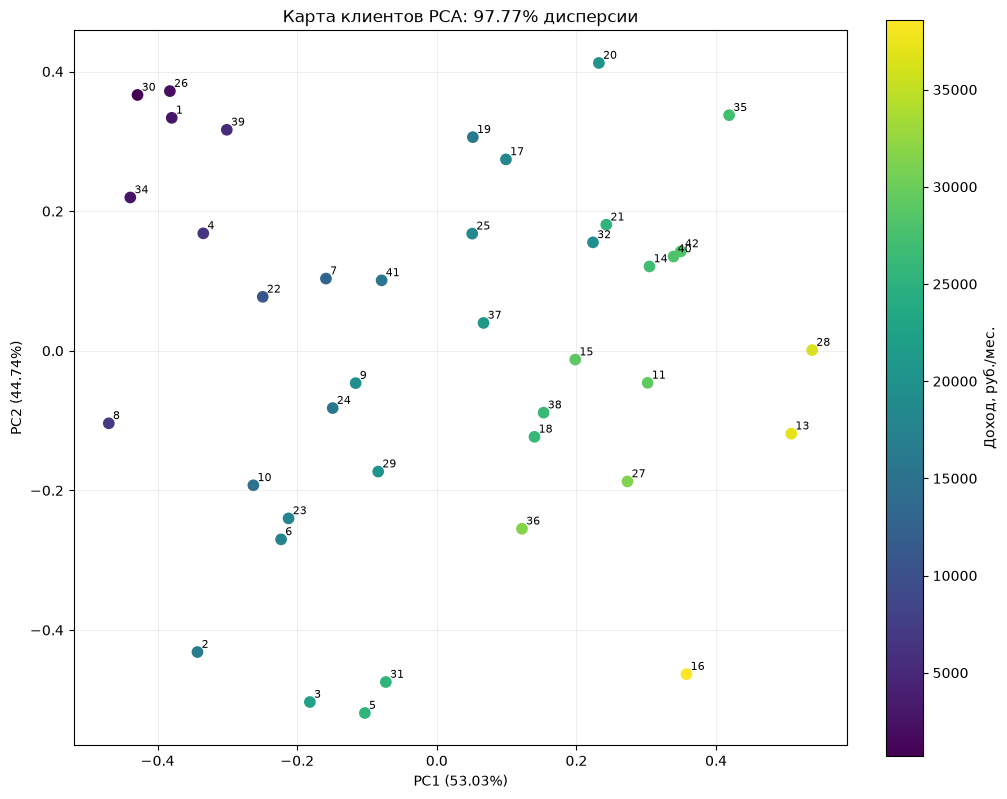

In [24]:
fig_pca, ax = plt.subplots(figsize=(10, 8), layout="constrained")

points = ax.scatter(
    Z_pca[:, 0],
    Z_pca[:, 1],
    c=df_clean["Доход"].to_numpy(),
    cmap="viridis",
    s=55,
)

offset = (3, 3)
for client_id, (x, y) in zip(client_ids_pca, Z_pca):
    ax.annotate(
        str(client_id),
        (x, y),
        xytext=offset,
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title(f"Карта клиентов PCA: {100 * cumulative_variance[1]:.2f}% дисперсии")
ax.set_xlabel(f"PC1 ({100 * explained_variance[0]:.2f}%)")
ax.set_ylabel(f"PC2 ({100 * explained_variance[1]:.2f}%)")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)

colorbar = fig_pca.colorbar(points, ax=ax)
colorbar.set_label("Доход, руб./мес.")

plt.show()

In [25]:
print("Коэффициенты направлений главных компонент:")
V_frame.iloc[:, :k].round(4)

Коэффициенты направлений главных компонент:


,PC1,PC2
Возраст,-0.3597,-0.4583
Иждивенцы,-0.2030,-0.5558
Доход,0.4949,-0.2778
Срок проживания,-0.4019,-0.4198
Стоимость автомобиля,0.4489,-0.3601
Размер кредита,0.4705,-0.3129


По таблице коэффициентов первая компонента противопоставляет финансовые показатели возрасту и сроку проживания: коэффициенты дохода, стоимости автомобиля и размера кредита положительны (примерно 0.495, 0.449 и 0.471), а возраста и срока проживания отрицательны (−0.360 и −0.402). Поэтому движение вправо связано с более высокими финансовыми показателями и, при прочих равных, меньшим возрастом и сроком проживания.

Во второй компоненте все коэффициенты отрицательны. Наибольшие по модулю относятся к числу иждивенцев (−0.556), возрасту (−0.458) и сроку проживания (−0.420). Увеличение этих характеристик связано с движением вниз по карте; финансовые показатели также имеют отрицательные коэффициенты.

In [26]:
client_profiles = df_clean.copy()
client_profiles.index = client_ids_pca

pca_correlations = pd.DataFrame(
    {
        name: client_profiles.corrwith(pca_coordinates[name])
        for name in component_names[:k]
    }
)

print("Корреляции признаков с координатами:")
pca_correlations.round(4)

Корреляции признаков с координатами:


,PC1,PC2
Возраст,-0.6416,-0.7509
Иждивенцы,-0.3621,-0.9107
Доход,0.8828,-0.4551
Срок проживания,-0.7168,-0.6879
Стоимость автомобиля,0.8008,-0.5900
Размер кредита,0.8393,-0.5127


### Примеры клиентов на карте

Выберем четырёх клиентов на исходной карте PCA: с минимальной и максимальной координатой PC1 (слева и справа), затем PC2 (снизу и сверху).

In [27]:
extreme_clients = pd.Series(
    {
        "Слева (минимум PC1)": pca_coordinates["PC1"].idxmin(),
        "Справа (максимум PC1)": pca_coordinates["PC1"].idxmax(),
        "Снизу (минимум PC2)": pca_coordinates["PC2"].idxmin(),
        "Сверху (максимум PC2)": pca_coordinates["PC2"].idxmax(),
    },
    name="Клиент",
)

extreme_profiles = pca_coordinates.join(client_profiles).loc[
    extreme_clients.to_numpy()
].copy()
extreme_profiles.insert(0, "Положение на карте", extreme_clients.index)

extreme_profiles.round(4)

,Положение на карте,PC1,PC2,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита
Клиент,,,,,,,,,
8,Слева (минимум PC1),-0.4698,-0.1039,51.0,3.0,7100.0,17.0,9000.0,82000.0
28,Справа (максимум PC1),0.5376,0.0010,31.0,1.0,36400.0,4.0,35000.0,355000.0
5,Снизу (минимум PC2),-0.1030,-0.5188,54.0,4.0,25400.0,18.0,28000.0,274000.0
20,Сверху (максимум PC2),0.2321,0.4122,27.0,0.0,20200.0,2.0,17000.0,185000.0


Проверим это на выбранных клиентах. Справа находится клиент 28: у него доход 36 400 руб./мес., возраст 31 год и срок проживания 4 года. Слева находится клиент 8: доход 7 100 руб./мес., возраст 51 год и срок проживания 17 лет. Эти различия согласуются со знаками коэффициентов PC1.

По второй координате сверху находится клиент 20 (27 лет, нет иждивенцев, 2 года проживания), а снизу клиент 5 (54 года, 4 иждивенца, 18 лет проживания). Это согласуется с отрицательными коэффициентами возраста, числа иждивенцев и срока проживания в PC2.

### 9. Расстояния Чебышева и возможность точного размещения на плоскости

Каждый клиент представлен шестью признаками. После заполнения пропусков
и удаления выбросов осталось 40 клиентов.

Признаки имеют разные единицы и масштабы, поэтому сначала стандартизируем
каждый столбец:

$$\widetilde{x}_{ik} = \frac{x_{ik} - \overline{x}_k}{s_k},
\qquad s_k = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ik}-\overline{x}_k)^2}.$$

Здесь $\overline{x}_k$ — среднее признака, $s_k$ — стандартное отклонение. Стандартизированные значения показывают отклонение от среднего
в единицах стандартного отклонения.

Используем расстояние Чебышева между стандартизированными векторами:

$$d_{ij} = \max_k |\widetilde{x}_{ik} - \widetilde{x}_{jk}|.$$

Оно показывает максимальное различие по одному признаку.
Матрица $D=(d_{ij})$ симметрична, имеет нулевую диагональ и размер $40\times40$.


In [28]:
df_scaled = (df_clean - df_clean.mean()) / df_clean.std(ddof=0)
X_mds = df_scaled.to_numpy(dtype=float)

D_chebyshev = np.abs(X_mds[:, None, :] - X_mds[None, :, :]).max(axis=2)

client_ids = pd.Index(df_clean.index + 1)
distances_chebyshev = pd.DataFrame(
    D_chebyshev,
    index=client_ids,
    columns=client_ids,
)
print(f"Размер матрицы расстояний: {D_chebyshev.shape}\n\n")
print(distances_chebyshev.round(3).head())

Размер матрицы расстояний: (40, 40)


      1      2      3      4      5      6      7      8      9      10  ...  \
1  0.000  2.829  2.829  0.943  2.829  1.886  1.113  1.886  1.688  1.886  ...   
2  2.829  0.000  0.648  2.171  0.941  0.943  2.044  1.113  1.886  0.943  ...   
3  2.829  0.648  0.000  2.044  0.293  0.943  1.916  1.720  1.886  0.943  ...   
4  0.943  2.171  2.044  0.000  2.184  1.533  0.673  1.533  1.342  1.277  ...   
5  2.829  0.941  0.293  2.184  0.000  0.943  1.886  2.007  1.886  1.202  ...   

      32     34     35     36     37     38     39     40     41     42  
1  2.383  0.943  2.479  3.136  1.902  2.466  0.303  2.561  1.315  2.581  
2  3.064  1.886  3.959  1.838  2.451  2.299  2.829  3.268  2.299  3.321  
3  2.860  2.428  3.832  1.634  2.299  2.171  2.829  3.065  2.171  3.193  
4  1.965  0.506  2.451  2.630  1.510  2.048  0.943  2.214  0.928  2.234  
5  2.829  2.630  3.772  1.430  2.171  2.044  2.829  2.938  2.044  3.065  

[5 rows x 40 columns]


Проверим возможность точного размещения в $\mathbb{R}^2$.

Для каждого клиента должна существовать точка $y_i=(u_i,v_i)$, такая что:

$$\|y_i-y_j\|_2 = \sqrt{(u_i-u_j)^2+(v_i-v_j)^2}=d_{ij}.$$

Пусть $Y$ - искомая матрица координат: каждая строка соответствует клиенту,
столбцы - координатам на плоскости. Матрица $YY^T$ содержит скалярные
произведения $y_i^Ty_j$. Их связь с исходными известными расстояниями:

$$d_{ij}^2 = \|y_i\|_2^2 + \|y_j\|_2^2 - 2y_i^Ty_j.$$

Обозначим
$S_{ij}=d_{ij}^2$ и $a_i=\|y_i\|_2^2$, $\mathbf{1}$ - столбец из $n$ единиц.. Тогда та же формула в матричной записи:

$$S = a\mathbf{1}^T + \mathbf{1}a^T - 2YY^T.$$

Перенос всех точек не меняет расстояния, поэтому выбираем начало координат
в их среднем. Центрирующая матрица

$$H = I_n - \frac{1}{n}\mathbf{1}\mathbf{1}^T$$

вычитает среднее из каждого столбца координат: $Y_c=HY$.
Здесь $I_n$ - единичная матрица, $\mathbf{1}$ - столбец из $n$ единиц.
Имеем $H\mathbf{1}=0$, $\mathbf{1}^TH=0$ и $H^T=H$.

Умножаем формулу для $S$ слева и справа на $H$:

$$HSH = Ha\mathbf{1}^TH + H\mathbf{1}a^TH - 2HYY^TH.$$

Первое слагаемое исчезает благодаря $\mathbf{1}^TH=0$, второе - благодаря
$H\mathbf{1}=0$. Одного умножения было бы недостаточно: одно из слагаемых
с квадратами длин осталось бы. Поэтому:

$$HSH = -2(HY)(HY)^T = -2Y_cY_c^T,$$
$$B = -\frac12 HSH = -\frac12 HD^{(2)}H.$$

Здесь $D^{(2)}_{ij}=d_{ij}^2$: матрица двадратов исходных длин.

Необходимость условий:

1. $B$ должна быть положительно полуопределена. Для любого вектора $c$:

   $$c^TBc=c^TY_cY_c^Tc=(Y_c^Tc)^T(Y_c^Tc)=\|Y_c^Tc\|_2^2\geq0.$$

   Квадрат длины неотрицателен. Для симметричной матрицы это равносильно
   неотрицательности всех собственных значений.
2. $\operatorname{rank}(B)\leq2$. У $Y_c$ только два столбца, поэтому:

   $$\operatorname{rank}(B)=\operatorname{rank}(Y_cY_c^T)
   =\operatorname{rank}(Y_c)\leq2.$$

Достаточность условий: 

Пусть $B$ положительно полуопределена и имеет
ранг $r\leq2$. Выполняем спектральное разложение $B=QTQ^T$.
В $Q_r$ оставляем собственные векторы для $r$ положительных собственных
значений, в $T_r$ - сами эти значения. Строим координаты:

$$Y_c=Q_rT_r^{1/2}.$$

Тогда $Y_cY_c^T=Q_rT_rQ_r^T=B$. У $Y_c$ не больше двух столбцов,
поэтому полученные точки размещаются на плоскости.

Проверим, что они сохраняют исходные расстояния. Пусть $m_i$ - среднее
строки $S$, $g$ - среднее всех элементов $S$. Двойное центрирование дает:

$$B_{ij}=-\frac12(S_{ij}-m_i-m_j+g).$$

Так как $S_{ii}=0$, имеем $B_{ii}=m_i-g/2$. Поэтому:

$$\|y_{c,i}-y_{c,j}\|_2^2=B_{ii}+B_{jj}-2B_{ij}=S_{ij}=d_{ij}^2.$$

Следовательно, оба условия вместе необходимы и достаточны для точного
размещения на евклидовой плоскости.


In [29]:
n_clients = len(df_clean)
H = np.eye(n_clients) - np.ones((n_clients, n_clients)) / n_clients
B = -0.5 * H @ (D_chebyshev**2) @ H
B = (B + B.T) / 2

eigenvalues = np.linalg.eigvalsh(B)
eps = 1e-10 * np.max(np.abs(eigenvalues))

n_positive = np.count_nonzero(eigenvalues > eps)
n_negative = np.count_nonzero(eigenvalues < -eps)
n_zero = np.count_nonzero(np.abs(eigenvalues) <= eps)
gram_rank = n_positive + n_negative
is_psd = n_negative == 0
can_embed_2d = is_psd and gram_rank <= 2

print(f"Минимальное собственное значение: {eigenvalues.min():.6f}")
print(f"Максимальное собственное значение: {eigenvalues.max():.6f}")
print(f"Положительных значений: {n_positive}")
print(f"Отрицательных значений: {n_negative}")
print(f"Нулевых значений: {n_zero}")
print(f"Численный ранг B: {gram_rank}")
print(f"B положительно полуопределена: {is_psd}")
print(f"Точное размещение в размерности 2 возможно: {can_embed_2d}")

Минимальное собственное значение: -7.771122
Максимальное собственное значение: 39.772768
Положительных значений: 22
Отрицательных значений: 17
Нулевых значений: 1
Численный ранг B: 39
B положительно полуопределена: False
Точное размещение в размерности 2 возможно: False


Матрица расстояний Чебышева имеет размер $40\times40$.

У матрицы $B$ 22 положительных, 17 отрицательных и 1 нулевое собственное
значение. Минимальное равно примерно −7.771. Ранг $B$ равен 39.

Точное размещение на евклидовой плоскости невозможно: $B$ не является
положительно полуопределенной, и ее ранг больше 2.
Отрицательные собственные значения исключают точное евклидово размещение
даже в большей размерности.

### 10. Карта клиентов: классический MDS

Используем классический MDS. На вход он получает матрицу
расстояний между объектами, а на выходе дает координаты объектов в пространстве
заданной размерности.

1. Берем расстояния Чебышева из пункта 9.
2. Используем полученную там матрицу $B$.
3. Находим собственные значения и собственные векторы $B$.
4. Оставляем два наибольших положительных собственных значения.
5. Получаем двумерные координаты каждого клиента:

$$B=QTQ^T, \qquad Z_{MDS}=Q_2T_2^{1/2}.$$

Отрицательные значения и остальные компоненты отбрасываем. Полученная
матрица $Z_{MDS}$ имеет размер 40 × 2. Ее строки - координаты клиентов.

Из пункта 9 следует, что точное сохранение всех расстояний на плоскости
невозможно, поэтому размещение будет приближенным.

In [30]:
mds_eigenvalues, mds_eigenvectors = np.linalg.eigh(B)
leading_indices = np.argsort(mds_eigenvalues)[::-1][:2]
leading_eigenvalues = mds_eigenvalues[leading_indices]
Z_mds = mds_eigenvectors[:, leading_indices] * np.sqrt(leading_eigenvalues)

mds_coordinates = pd.DataFrame(
    Z_mds,
    index=pd.Index(client_ids),
    columns=["X", "Y"],
)
print("Использованные собственные значения:", leading_eigenvalues.round(6))
mds_coordinates.head()

Использованные собственные значения: [39.772768 34.922813]


,X,Y
1,-0.828264,1.572153
2,-1.708375,-1.091318
3,-1.481178,-1.250577
4,-0.875855,0.920152
5,-1.302409,-1.314354


Оценим погрешность путем вычисления евклидовых расстояний
$\widehat{d}_{ij}$ и сравнением их с исходными расстояниями Чебышева $d_{ij}$ для всех пар.

В качестве метрик используем:

 - $ \sqrt{\frac{\sum_{i<j}(\widehat{d}_{ij}-d_{ij})^2}
{\sum_{i<j}d_{ij}^2}}$ - относительная ошибка
 - RMSE - корень квадратный из среднеквадратичной ошибки
 - $\max_{i<j}|\widehat{d}_{ij}-d_{ij}|$ - максимальная абсолютная ошибка


In [31]:
D_mds = np.linalg.norm(
    Z_mds[:, None, :] - Z_mds[None, :, :], axis=2,
)
pair_indices = np.triu_indices(n_clients, k=1)
original_distances = D_chebyshev[pair_indices]
distance_errors = D_mds[pair_indices] - original_distances

relative_error = np.linalg.norm(distance_errors) / np.linalg.norm(original_distances)
rmse = np.sqrt(np.mean(distance_errors ** 2))
absolute_errors = np.abs(distance_errors)
median_error, p90_error = np.percentile(absolute_errors, [50, 90])
max_error = np.max(absolute_errors)

mds_errors = pd.DataFrame({
    "Относительная ошибка": [relative_error],
    "RMSE": [rmse],
    "P50 абсолютной ошибки": [median_error],
    "P90 абсолютной ошибки": [p90_error],
    "Максимальная ошибка": [max_error],
}, index=["Классический MDS"])
mds_errors.round(4)

,Относительная ошибка,RMSE,P50 абсолютной ошибки,P90 абсолютной ошибки,Максимальная ошибка
Классический MDS,0.1129,0.2243,0.1162,0.344,1.1406


- Среднеквадратичная ошибка 0.2243 составляет примерно 1/9 исходного
среднеквадратичного расстояния (11.29%).
- Медиана ошибки = 0.1162: у половины пар ошибка не превышает 0.12.
  Это почти вдвое меньше RMSE: крупные ошибки части пар заметно повышают
  среднеквадратичную оценку.
- P90 = 0.3440: у 90% пар абсолютная ошибка не превышает порога P90.
  У 78 из 780 пар ошибка больше этого порога. Максимальная ошибка
  равна 1.1406.

Карта подходит для приблизительного обзора клиентов, но точное сравнение
пар и выбор ближайшего клиента нужно проверять по исходным расстояниям.


### Карта клиентов

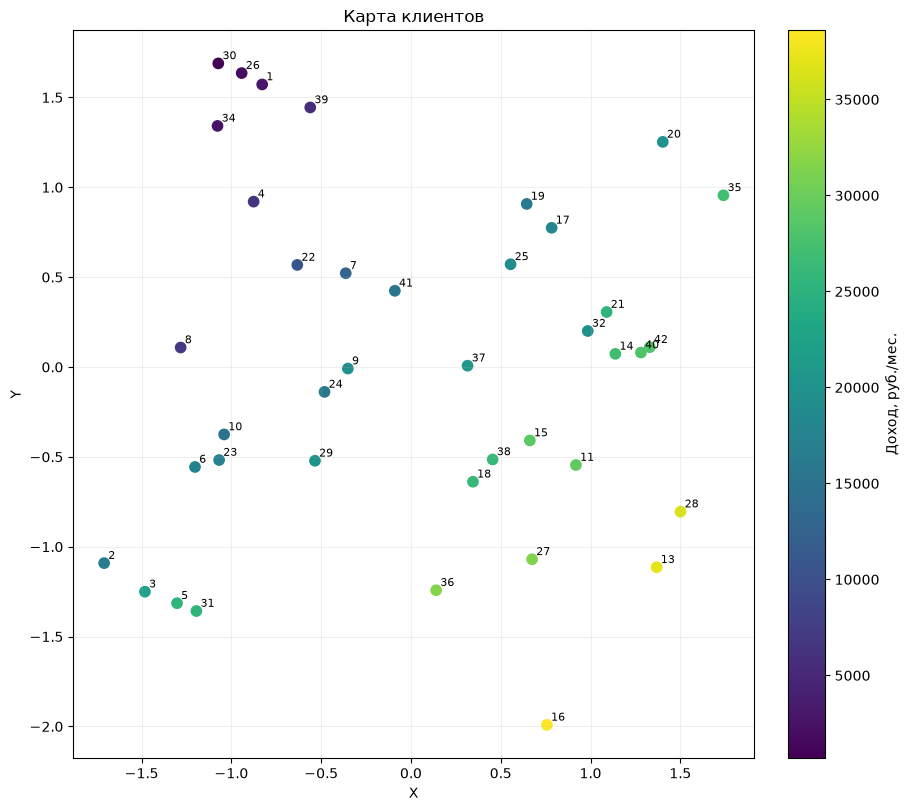

In [32]:
fig_map, ax = plt.subplots(figsize=(9, 8), layout="constrained")
points = ax.scatter(
    Z_mds[:, 0],
    Z_mds[:, 1],
    c=df_clean["Доход"].to_numpy(),
    s=55,
)
offset = (3, 3)
for client_id, (x, y) in zip(client_ids, Z_mds):
    ax.annotate(
        str(client_id),
        (x, y),
        xytext=offset,
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title(f"Карта клиентов")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.grid(alpha=0.2)
colorbar = fig_map.colorbar(points, ax=ax)
colorbar.set_label("Доход, руб./мес.")
plt.show()

Выводы
- На карте заметен переход от клиентов с низкими доходами к клиентам
  с более высокими. Близкие точки приблизительно соответствуют похожим
  клиентам.
- Есть искажения расстояний. Близость на карте не гарантирует
  точного совпадения профилей, а видимые скопления сами по себе
  не доказывают наличие отдельных кластеров.

Получено приближенное размещение 40 клиентов на евклидовой плоскости.
Ненулевая ошибка согласуется с результатом пункта 9.

### Сравнение с PCA

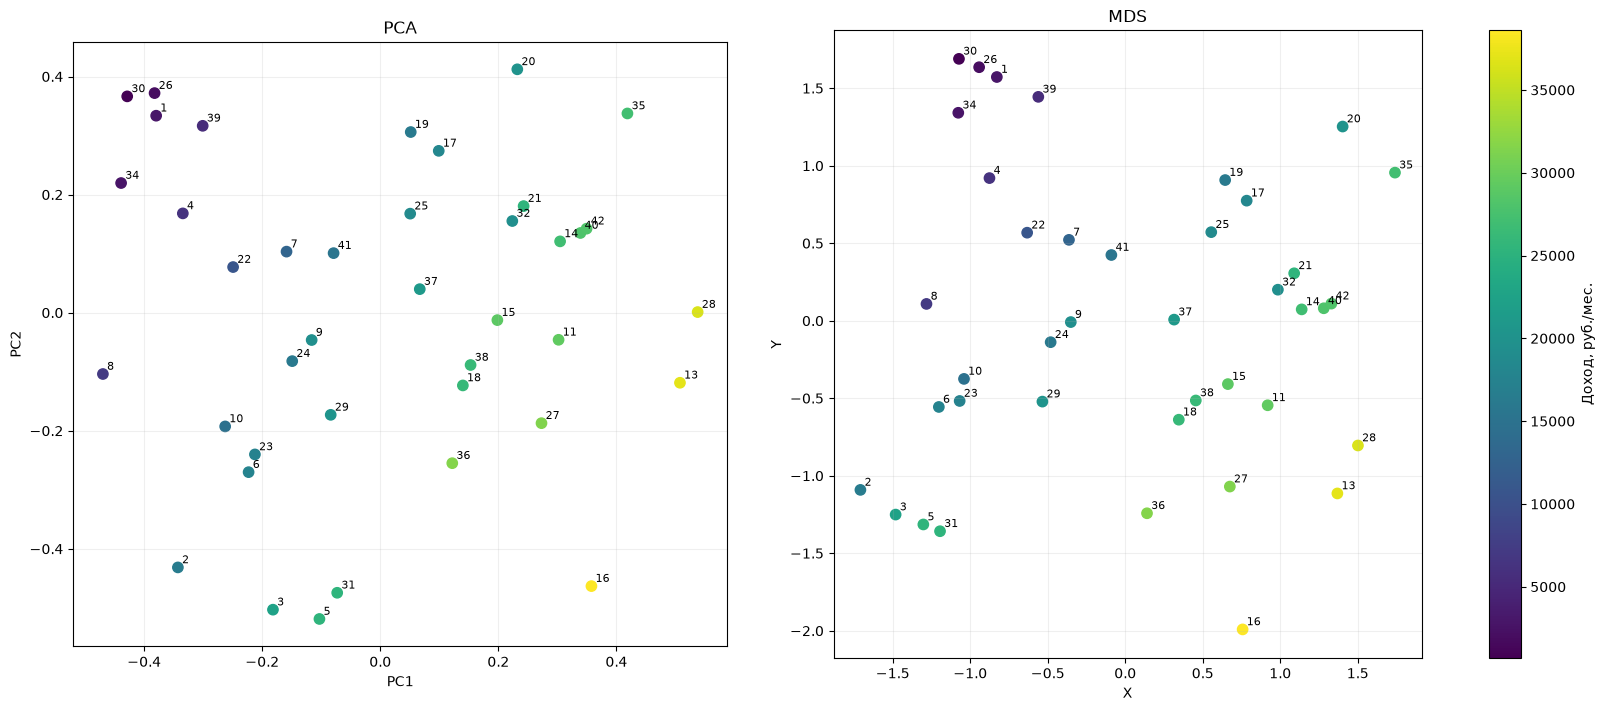

In [33]:
comparison_ids = pd.Index(df_clean.index + 1)
comparison_income = df_clean["Доход"].to_numpy()
income_norm = plt.Normalize(comparison_income.min(), comparison_income.max())

comparison_maps = [
    ("PCA", pca_coordinates.loc[comparison_ids].to_numpy(), "PC1", "PC2"),
    ("MDS", mds_coordinates.loc[comparison_ids].to_numpy(), "X", "Y"),
]

fig_comparison, axes = plt.subplots(
    1, 2, figsize=(16, 7), layout="constrained",
)

for ax, (title, coordinates, xlabel, ylabel) in zip(axes, comparison_maps):
    points = ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        c=comparison_income,
        cmap="viridis",
        norm=income_norm,
        s=55,
    )
    for client_id, (x, y) in zip(comparison_ids, coordinates):
        ax.annotate(
            str(client_id),
            (x, y),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=8,
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

colorbar = fig_comparison.colorbar(points, ax=axes)
colorbar.set_label("Доход, руб./мес.")

plt.show()

В целом взаимное расположение клиентов на картах PCA и MDS похоже: например, клиенты 30, 26, 1 находятся рядом на обеих картах, как и клиенты 14, 40, 42. На обеих картах также заметен переход от клиентов с более низкими доходами к клиентам с более высокими.

При этом методы строят карты по разным критериям. PCA использует две главные компоненты, которые вместе объясняют 97.77% дисперсии, а MDS стремится сохранить расстояния Чебышева между клиентами. Несмотря на разные принципы построения, обе карты показывают схожее взаимное расположение клиентов.